# Desafio 02 — Investigue uma pergunta com Python
## Exemplo de entrega: desempenho e frequência escolar

> **Projeto didático com dados fictícios.** Os registros foram simulados para demonstrar análise exploratória. Não representam estudantes reais nem uma escola específica.

**Equipe:** [Inserir nomes dos integrantes]

[Notebook preparado para execução no Jupyter ou Google Colab.]

## 1. A base escolhida

Escolhemos uma base simulada de acompanhamento escolar com registros de 540 estudantes, acrescida de algumas duplicatas para demonstrar o processo de limpeza. Ela contém turma, idade, frequência, notas de avaliações, média final e data de registro.

A escolha permite investigar questões relevantes para uma equipe pedagógica: relação entre presença e desempenho, diferenças entre turmas e possíveis necessidades de acompanhamento.

### Dicionário das variáveis

| Coluna | Descrição |
|---|---|
| `id_estudante` | identificador fictício do registro |
| `data_registro` | data associada ao registro |
| `turma` | turma do estudante |
| `idade` | idade em anos |
| `frequencia_pct` | frequência em percentual |
| `nota_av1`, `nota_av2`, `nota_av3` | notas das avaliações |
| `media_final` | média final registrada |

## 2. As perguntas

1. **Existe associação entre frequência escolar e média final?**
2. **Quais turmas apresentam as maiores e menores médias finais?**
3. **Estudantes com frequência igual ou superior a 85% apresentam média final diferente dos estudantes com frequência inferior a 85%?** Esta pergunta compara dois grupos e será respondida com um teste de hipótese.

Essas perguntas podem ajudar uma equipe escolar a identificar padrões, acompanhar turmas e planejar ações pedagógicas. Como a base é fictícia, as conclusões são apenas uma demonstração do método.

## 3. Preparação dos dados
### 3.1 Carregar e conhecer a base

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

ARQUIVO = 'dados/base_escolar_original.csv'
df_original = pd.read_csv(ARQUIVO)
df = df_original.copy()

print('Dimensões (linhas, colunas):', df.shape)
display(df.head())
df.info()

Dimensões (linhas, colunas): (552, 9)


,id_estudante,data_registro,turma,idade,frequencia_pct,nota_av1,nota_av2,nota_av3,media_final
0,AL0001,2026-03-02,8º B,13,86.1,2.4,3.3,2.9,2.9
1,AL0002,03/03/2026,6º B,11,95.4,6.6,8.2,6.9,7.2
2,AL0003,04/03/2026,6º A,11,85.0,5.4,5.8,7.7,6.3
3,AL0004,2026-03-05,7º B,13,100.0,8.4,5.8,7.1,7.1
4,AL0005,06/03/2026,7º A,13,89.7,4.2,4.8,4.7,4.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 552 entries, 0 to 551
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_estudante    552 non-null    object 
 1   data_registro   552 non-null    object 
 2   turma           552 non-null    object 
 3   idade           552 non-null    int64  
 4   frequencia_pct  544 non-null    float64
 5   nota_av1        552 non-null    float64
 6   nota_av2        545 non-null    float64
 7   nota_av3        552 non-null    float64
 8   media_final     552 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 38.9+ KB


### 3.2 Investigar linhas duplicadas

In [2]:
duplicadas = df.duplicated().sum()
print('Linhas duplicadas:', duplicadas)

df = df.drop_duplicates().copy()
print('Linhas depois de remover duplicatas:', len(df))

Linhas duplicadas: 12
Linhas depois de remover duplicatas: 540


As linhas duplicadas são cópias exatas e poderiam contar o mesmo registro mais de uma vez. Por isso, removemos as duplicatas da cópia de trabalho. O arquivo original continua preservado na pasta `dados/`.

### 3.3 Verificar valores ausentes e tipos

In [3]:
print('Tipos de dados:')
display(df.dtypes)
print('Valores ausentes por coluna:')
display(df.isna().sum())

Tipos de dados:


id_estudante       object
data_registro      object
turma              object
idade               int64
frequencia_pct    float64
nota_av1          float64
nota_av2          float64
nota_av3          float64
media_final       float64
dtype: object

Valores ausentes por coluna:


id_estudante      0
data_registro     0
turma             0
idade             0
frequencia_pct    8
nota_av1          0
nota_av2          7
nota_av3          0
media_final       0
dtype: int64

Há valores ausentes em algumas variáveis numéricas. Não vamos preencher notas ou frequência com médias inventadas. Para cada análise, usaremos os registros que tenham os campos necessários. Também converteremos a data para o tipo apropriado.

### 3.4 Padronizar categorias e datas

In [4]:
# Padronizar espaços e letras nas categorias de turma.
df['turma'] = df['turma'].astype('string').str.strip().str.upper()

# Converter datas em formato dia/mês/ano ou ano-mês-dia.
data_texto = df['data_registro'].astype('string')
data_a = pd.to_datetime(data_texto, format='%d/%m/%Y', errors='coerce')
data_b = pd.to_datetime(data_texto, format='%Y-%m-%d', errors='coerce')
df['data_registro'] = data_a.fillna(data_b)

print('Datas não convertidas:', df['data_registro'].isna().sum())
print('Categorias de turma:', sorted(df['turma'].dropna().unique()))

Datas não convertidas: 0
Categorias de turma: ['6º A', '6º B', '7º A', '7º B', '8º A', '8º B']


### 3.5 Investigar valores fora dos limites esperados

In [5]:
colunas_num = ['idade','frequencia_pct','nota_av1','nota_av2','nota_av3','media_final']
for col in colunas_num:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Frequência acima de 100%:')
display(df[df['frequencia_pct'] > 100][['id_estudante','turma','frequencia_pct']])
print('Média final fora da escala de 0 a 10:')
display(df[~df['media_final'].between(0,10)][['id_estudante','turma','media_final']])

Frequência acima de 100%:


,id_estudante,turma,frequencia_pct
300,AL0301,6º A,150.0


Média final fora da escala de 0 a 10:


,id_estudante,turma,media_final
400,AL0401,8º B,15.0


A frequência deve estar entre 0% e 100%, e as notas entre 0 e 10. Valores fora desses intervalos são inconsistentes para esta base simulada. Vamos marcá-los como ausentes, sem tentar adivinhar qual seria o valor correto.

In [6]:
df.loc[~df['frequencia_pct'].between(0,100), 'frequencia_pct'] = np.nan
df.loc[~df['media_final'].between(0,10), 'media_final'] = np.nan

# Criar uma base tratada, mantendo registros com turma e campos válidos.
df = df.dropna(subset=['turma','data_registro']).copy()
df['turma'] = df['turma'].replace({'6º A':'6º A','6º B':'6º B','7º A':'7º A',
                                   '7º B':'7º B','8º A':'8º A','8º B':'8º B'})
df.to_csv('dados/base_escolar_tratada.csv', index=False, encoding='utf-8-sig')

print('Dimensão da base tratada:', df.shape)
print('Ausências após tratamento:')
display(df.isna().sum())

Dimensão da base tratada: (540, 9)
Ausências após tratamento:


id_estudante      0
data_registro     0
turma             0
idade             0
frequencia_pct    9
nota_av1          0
nota_av2          7
nota_av3          0
media_final       1
dtype: int64

A base tratada foi salva separadamente. A base original não foi sobrescrita. Ausências em notas e frequência foram mantidas quando não impedem as outras análises; cada cálculo utilizará apenas os campos de que precisa.

## 4. Análise
### Pergunta 1 — Existe associação entre frequência e média final?

Primeiro, calculamos a correlação de Pearson usando apenas registros que tenham frequência e média final válidas.

Registros usados: 530
Correlação de Pearson: 0.310


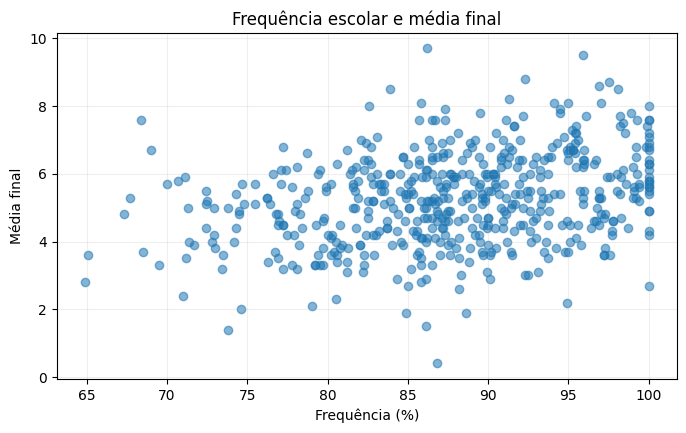

In [7]:
dados_corr = df[['frequencia_pct','media_final']].dropna()
correlacao = dados_corr['frequencia_pct'].corr(dados_corr['media_final'])
print('Registros usados:', len(dados_corr))
print(f'Correlação de Pearson: {correlacao:.3f}')

fig, ax = plt.subplots(figsize=(8,4.5))
ax.scatter(dados_corr['frequencia_pct'], dados_corr['media_final'], alpha=.55)
ax.set_xlabel('Frequência (%)')
ax.set_ylabel('Média final')
ax.set_title('Frequência escolar e média final')
ax.grid(alpha=.2)
plt.show()

**Interpretação:** a correlação varia de -1 a +1. Um valor positivo indica que maior frequência tende a aparecer junto de médias maiores; um valor negativo indica tendência inversa. Correlação não demonstra que uma variável cause a outra.

### Pergunta 2 — Quais turmas apresentam maiores e menores médias?

,quantidade,media,mediana,desvio_padrao
turma,,,,
6º A,92,5.50,5.50,1.43
8º A,76,5.34,5.30,1.38
7º B,98,5.31,5.20,1.27
7º A,96,5.29,5.35,1.42
6º B,93,5.12,5.00,1.25
8º B,84,5.05,5.25,1.38


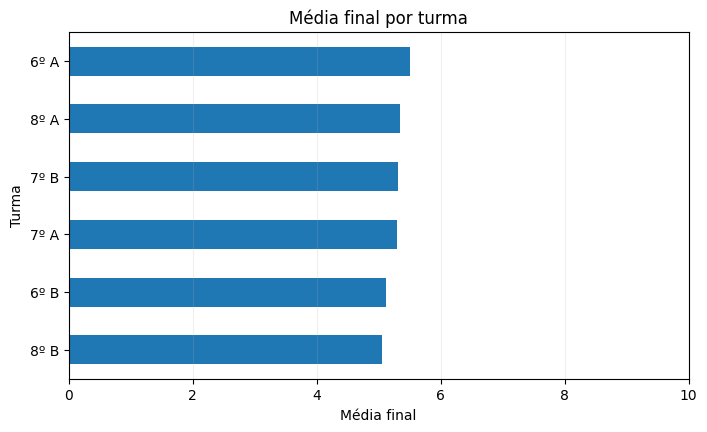

In [8]:
resumo_turmas = (df.groupby('turma')['media_final']
                  .agg(quantidade='count', media='mean',
                       mediana='median', desvio_padrao='std')
                  .sort_values('media', ascending=False)
                  .round(2))
display(resumo_turmas)

fig, ax = plt.subplots(figsize=(8,4.5))
resumo_turmas['media'].sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Média final')
ax.set_ylabel('Turma')
ax.set_title('Média final por turma')
ax.set_xlim(0,10)
ax.grid(axis='x', alpha=.2)
plt.show()

**Interpretação:** a tabela permite comparar quantidade de registros, média e dispersão por turma. A média mais alta não significa, sozinha, que uma turma tenha melhor ensino: diferenças de contexto e composição dos grupos não estão representadas na base.

### Pergunta 3 — A média difere entre estudantes com frequência ≥ 85% e frequência < 85%?

Antes do teste, comparamos as quantidades e as médias dos dois grupos.

Frequência ≥ 85%: n=362, média=5.48
Frequência < 85%: n=168, média=4.80


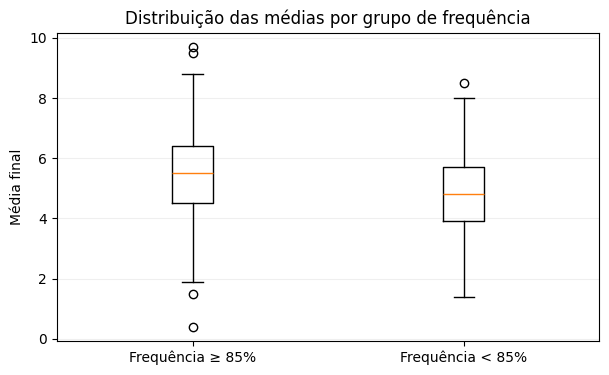

In [9]:
base_teste = df[['frequencia_pct','media_final']].dropna().copy()
grupo_alta = base_teste.loc[base_teste['frequencia_pct'] >= 85, 'media_final']
grupo_baixa = base_teste.loc[base_teste['frequencia_pct'] < 85, 'media_final']

print(f'Frequência ≥ 85%: n={len(grupo_alta)}, média={grupo_alta.mean():.2f}')
print(f'Frequência < 85%: n={len(grupo_baixa)}, média={grupo_baixa.mean():.2f}')

fig, ax = plt.subplots(figsize=(7,4))
ax.boxplot([grupo_alta, grupo_baixa],
           tick_labels=['Frequência ≥ 85%','Frequência < 85%'])
ax.set_ylabel('Média final')
ax.set_title('Distribuição das médias por grupo de frequência')
ax.grid(axis='y', alpha=.2)
plt.show()

## 5. Teste de hipótese

- **Hipótese nula (H₀):** a média final dos dois grupos é igual.
- **Hipótese alternativa (H₁):** as médias finais dos dois grupos são diferentes.
- **Nível de significância:** 5% (α = 0,05).

Usamos o **teste t de Welch para duas amostras independentes**, que não exige que os grupos tenham variâncias iguais.

In [10]:
resultado = stats.ttest_ind(grupo_alta, grupo_baixa, equal_var=False)
diferenca = grupo_alta.mean() - grupo_baixa.mean()

print(f'Média com frequência ≥ 85%: {grupo_alta.mean():.2f} (n={len(grupo_alta)})')
print(f'Média com frequência < 85%: {grupo_baixa.mean():.2f} (n={len(grupo_baixa)})')
print(f'Diferença entre as médias: {diferenca:.2f}')
print(f'Estatística t: {resultado.statistic:.3f}')
print(f'Valor-p: {resultado.pvalue:.6g}')
print('Rejeitamos H₀' if resultado.pvalue < 0.05 else 'Não rejeitamos H₀')

Média com frequência ≥ 85%: 5.48 (n=362)
Média com frequência < 85%: 4.80 (n=168)
Diferença entre as médias: 0.68
Estatística t: 5.764
Valor-p: 1.76318e-08
Rejeitamos H₀


**Como interpretar:** se o valor-p for menor que 0,05, rejeitamos H₀. Isso indica que a diferença observada seria pouco compatível com a hipótese de médias iguais, considerando o modelo do teste. Não significa que a frequência seja a única causa do desempenho.

## 6. Conclusões

In [11]:
medias = df.groupby('turma')['media_final'].mean().dropna().sort_values(ascending=False)
print(f'Correlação entre frequência e média: {correlacao:.3f}.')
print(f'Turma com maior média: {medias.index[0]} ({medias.iloc[0]:.2f}).')
print(f'Turma com menor média: {medias.index[-1]} ({medias.iloc[-1]:.2f}).')
print(f'Diferença média entre grupos de frequência: {diferenca:.2f} ponto(s).')
print(f'Valor-p do teste de Welch: {resultado.pvalue:.6g}.')

Correlação entre frequência e média: 0.310.
Turma com maior média: 6º A (5.50).
Turma com menor média: 8º B (5.05).
Diferença média entre grupos de frequência: 0.68 ponto(s).
Valor-p do teste de Welch: 1.76318e-08.


### Síntese dos achados

1. A correlação resume a associação entre frequência e média final na base simulada.
2. O agrupamento permite identificar quais turmas aparecem com médias mais altas e mais baixas.
3. O teste de Welch avalia se as médias dos grupos de frequência apresentam diferença estatística.

**Recomendação simulada:** em uma aplicação real, a equipe pedagógica poderia usar os resultados como sinal para investigar estudantes com baixa frequência e turmas que necessitem de acompanhamento, sempre analisando também o contexto de cada caso.

### Limitações

- A base é inteiramente fictícia e não representa uma escola real.
- A associação entre frequência e nota não prova causalidade.
- Não foram incluídos fatores como contexto familiar, condições de ensino ou características das avaliações.
- A conclusão do teste depende da qualidade dos dados e das condições do método estatístico.

## 7. Reflexão

- **O que ficou mais fácil em Python:** verificar e tratar centenas de registros, padronizar categorias, agrupar turmas, gerar gráficos e executar um teste estatístico de forma reproduzível.
- **Como a equipe dividiu o trabalho:** preencher com a divisão real feita pelos integrantes. Uma possibilidade é dividir entre preparação da base, análise exploratória, teste estatístico e revisão das conclusões.

## 8. Como executar

1. Instale Python 3.10 ou mais recente.
2. Na pasta do projeto, instale as bibliotecas com `pip install -r requirements.txt`.
3. Abra o notebook no JupyterLab ou Google Colab.
4. Execute **Restart & Run All** / **Executar tudo**.

O notebook procura os arquivos na pasta `dados/`, que deve permanecer ao lado do arquivo `.ipynb`.